In [31]:
import matplotlib.pyplot as plt
import re
import pandas as pd
import seaborn as sns

In [32]:
target_stack = "['lr', 'svc']"
meta = []
accuracy = []

with open('stacks.txt', 'r') as f:
    for line in f:
        stack_match = re.search(r"Stack: (\[.*?\])", line)
        meta_match = re.search(r"Meta: ([^|]+)", line)
        acc_match = re.search(r"Accuracy: ([\d\.]+)", line)
        if stack_match and meta_match and acc_match:
            stack = stack_match.group(1)
            if stack == target_stack:
                meta.append(meta_match.group(1).strip())
                accuracy.append(float(acc_match.group(1)))
print(meta)
print(accuracy)

['LogisticRegression', 'RidgeClassifier', 'RandomForestClassifier', 'GradientBoostingClassifier', 'AdaBoostClassifier', 'ExtraTreesClassifier', 'HistGradientBoostingClassifier', 'SVC', 'KNeighborsClassifier', 'GaussianNB', 'BernoulliNB', 'DecisionTreeClassifier', 'BaggingClassifier', 'MLPClassifier', 'LGBMClassifier', 'XGBClassifier']
[0.8621, 0.8621, 0.1379, 0.1379, 0.1379, 0.1379, 0.1379, 0.8621, 0.1379, 0.8621, 0.8621, 0.1379, 0.1379, 0.8621, 0.1379, 0.1379]


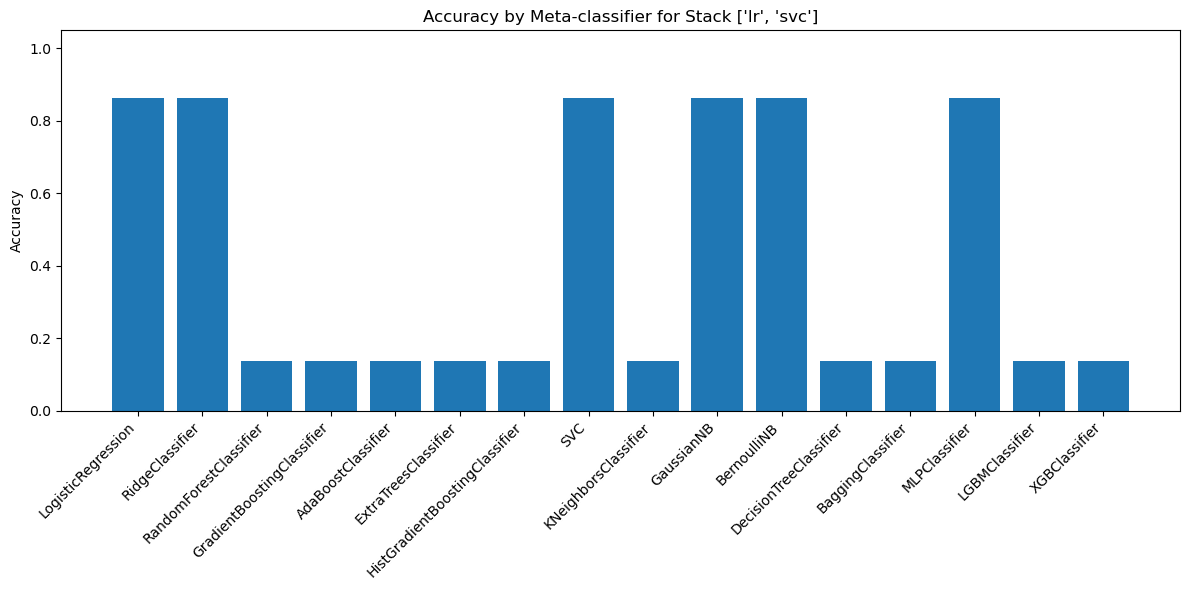

In [33]:
plt.figure(figsize=(12, 6))
plt.bar(meta, accuracy)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Accuracy')
plt.title(f'Accuracy by Meta-classifier for Stack {target_stack}')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

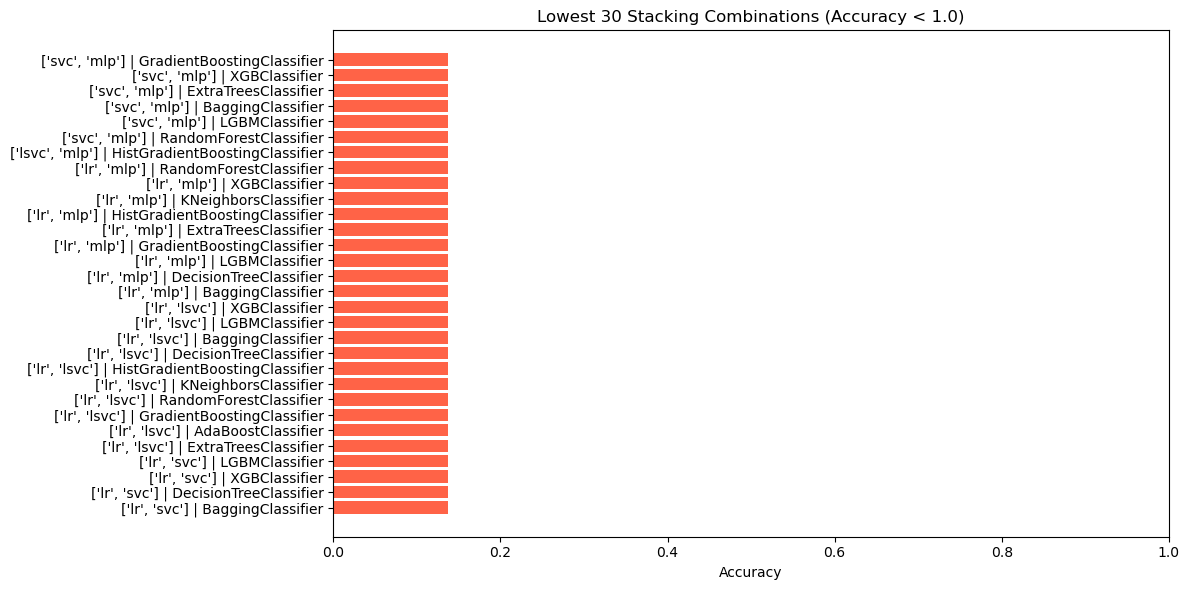

In [34]:
data = []
with open('stacks.txt', 'r') as f:
    for line in f:
        stack_match = re.search(r"Stack: (\[.*?\])", line)
        meta_match = re.search(r"Meta: ([^|]+)", line)
        acc_match = re.search(r"Accuracy: ([\d\.]+)", line)
        if stack_match and meta_match and acc_match:
            acc = float(acc_match.group(1))
            if acc < 1.0:
                data.append({
                    'stack': stack_match.group(1),
                    'meta': meta_match.group(1).strip(),
                    'accuracy': acc
                })

df = pd.DataFrame(data)
df['label'] = df['stack'] + ' | ' + df['meta']

# Sort by accuracy
df = df.sort_values('accuracy')

N = 30
plt.figure(figsize=(12, 6))
plt.barh(df['label'].head(N), df['accuracy'].head(N), color='tomato')
plt.xlabel('Accuracy')
plt.title(f'Lowest {N} Stacking Combinations (Accuracy < 1.0)')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()